In [1]:
import numpy as np

from particle_filter.filtering_algorithms.particle_filter import BootstrapParticleFilter, AuxiliaryParticleFilter

from particle_filter.models.noise import GaussianNoise
from particle_filter.models.transition import AdditiveTransitionModel
from particle_filter.models.observation import AdditiveObservationModel

from particle_filter.simulations import system_simulation

from particle_filter.plots.plot_results import plot_results
from particle_filter.plots.plot_comparisons import plot_comparisons

from particle_filter.performance_metrics import RMSE

# PENDULO
Un péndulo (sin control) suele modelarse en espacio de estados como:

$$
x = 
\begin{bmatrix}
\theta \\
\omega
\end{bmatrix}
$$

con 
- $\theta$: ángulo
- $\omega$: velocidad angular

Ecuación continua:

$$
\dot{\theta} = \omega \\
\dot{\omega} = -\frac{g}{L}sin(\theta)
$$

### Discretización
Dado que se trabaja con el tiempo discreto, se necesita realizar una aproximación numérica. En este caso se ha tomado Euler.

La idea es aproximar las derivadas como:

$$
x´(t)\approx \frac{x_{n+1} - x_n}{\Delta t} 
$$

y despejando:

$$
x_{n+1} = x_n + \Delta t \;x´(t_n)
$$

Por lo tanto, tras la discretización, las ecuacciones del péndulo quedan:

$$
\theta_{n+1} = \theta_{n} + \Delta t\;w_n \\
w_{n+1} = w_n - \Delta t\; \frac{g}{L}\;sin(\theta_n)
$$

Depende mucho del valor de $\Delta_t$ y no conservar la energía provocando que el péndulo gane energía artificial (oscilaciones cada vez más grandes) o perder energía (amortiguamiento artificial).

### Observación

En este ejemplo se tiene el caso en el que solamente se mide el ángulo:

$$
y_t = \theta_t + v_t
$$

### Ecuación en espacio de estados

Finalmente, el modelo en espacio de estados tiene la siguiente forma

- Vector estado

$$
x_k = \begin{bmatrix}
\theta_k \\
\omega_k
\end{bmatrix}
$$

- Modelo dinámico 

$$
x_{k+1} = \begin{bmatrix}
\theta_k + \omega_k\; \Delta_t \\
\omega_k - \frac{g}{L}\;sin(\theta_k)\;\Delta_t
\end{bmatrix}
+ w_k
$$

- Modelo de medición

$$
y_k = \begin{bmatrix} 1 &0 \end{bmatrix} x_k + v_k
$$

con 

$$
w_k \sim \mathcal{N}(0, Q)\quad \quad v_k \sim \mathcal{N}(0, R)\\\\[2ex]

Q = \begin{bmatrix}

10^{-4} &0\\
0 &10^{-3}
\end{bmatrix}

\quad \quad

R = \begin{bmatrix} 10^{-2} \end{bmatrix}
$$

In [2]:
# Definición función de transición
g = 9.81
L = 1.0
dt = 0.01

def f(x):
    theta, omega = x

    omega_dot = -(g / L) * np.sin(theta)

    theta_next = theta + omega * dt
    omega_next = omega + omega_dot * dt

    theta_next = (theta_next + np.pi) % (2*np.pi) - np.pi

    return np.array([theta_next, omega_next])

In [3]:
# Definicion funcion de medicion
def h(x):
    theta, _ = x

    return np.array([theta])

In [4]:
# Definicion ruido
Q = np.diag([1e-4, 1e-3]) #ruido de proceso
R = np.array([1e-2]) #ruido de medicion

In [5]:
# Definicion modelos
noise_transition = GaussianNoise(Q)
transition = AdditiveTransitionModel(f, noise_transition)

noise_observation = GaussianNoise(R)
observation = AdditiveObservationModel(h, noise_observation) 

In [6]:
# Simulacion
T = 500
x0 = np.array([
    np.deg2rad(45), # 45 grados iniciales
    0.0             # sin velocidad inicial 
])

x_true, y_obs = system_simulation(transition, observation, x0, T)

### Comparacion Bootstrap Filter con y sin re-muestreo

In [7]:
bpf = BootstrapParticleFilter(
    N=1000,
    transition_model=transition,
    observation_model=observation
)

bpf.initialize(mean=np.array([0.0, 0.0]), cov=np.eye(2))

est_bpf = bpf.run_filter(y_obs, resample_threshold=500)

In [8]:
bpf.reset(mean=np.array([0.0, 0.0]), cov=np.eye(2))

est_bpf_no_resample = bpf.run_filter(y_obs)

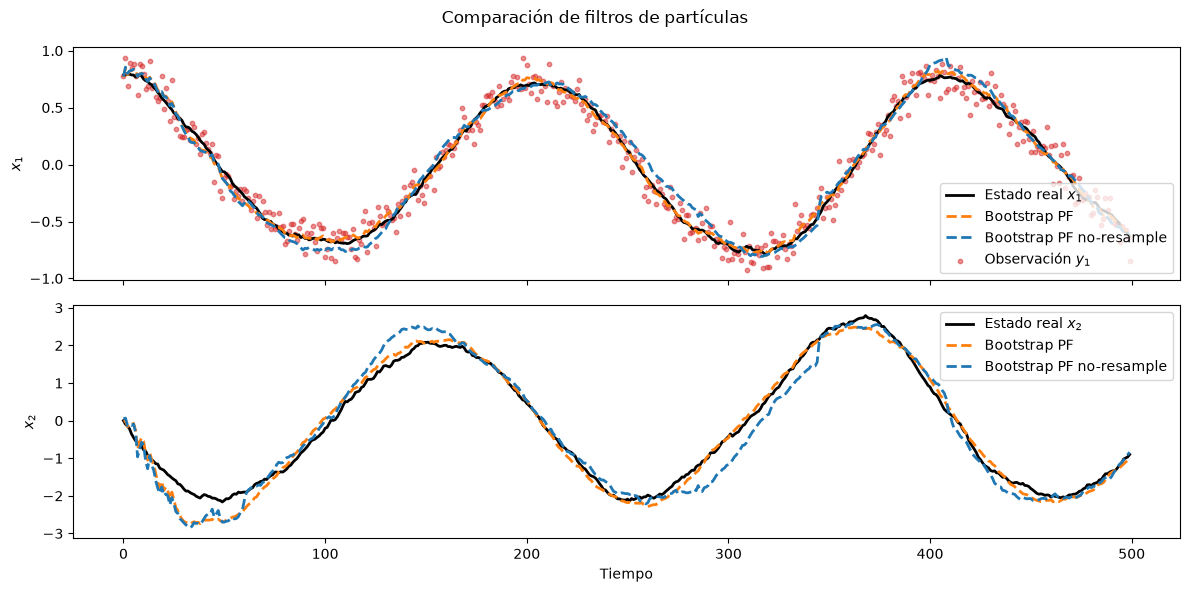

In [9]:
#-----Plot Bootstrap Particle Filter-----
estimates = {
    "Bootstrap PF": est_bpf["estimates"],
    "Bootstrap PF no-resample":est_bpf_no_resample["estimates"]
}

plot_results(x_true, y_obs, estimates)

Tiempo de ejecución: 45.29452379979193

Numero de re-muestreos: 53

Log-verosimilitud estimada: 413.77738361478185



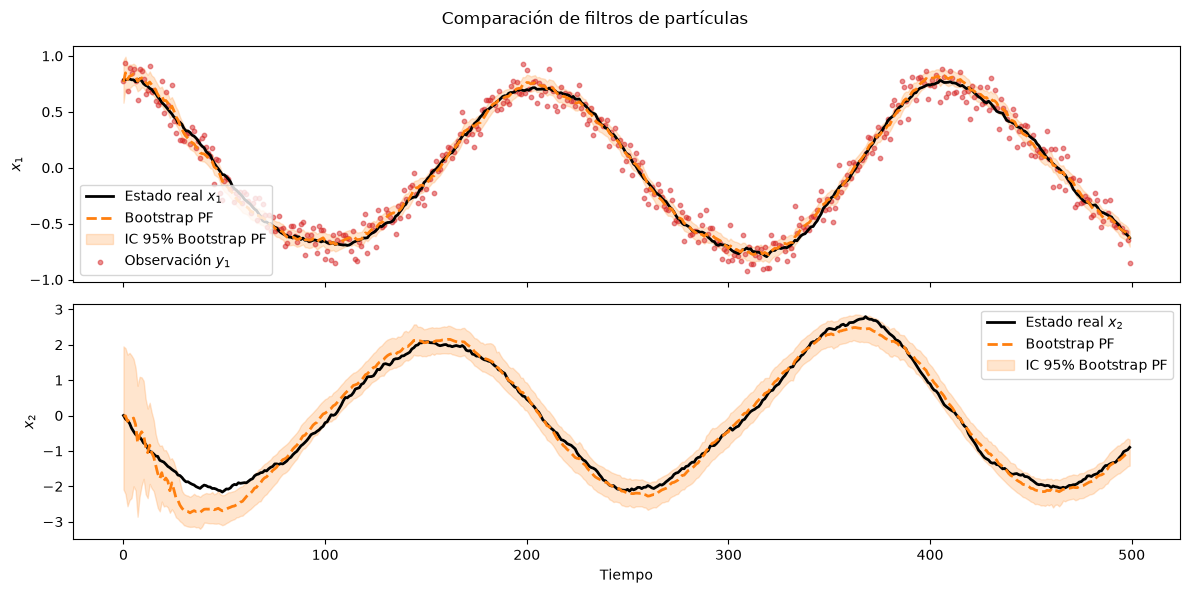

In [11]:
#----Plot Bootstrap Particle Filter con re-muestreo e info----
print(f"Tiempo de ejecución: {est_bpf["execution_time"]}\n")
print(f"Numero de re-muestreos: {est_bpf["number_resamples"]}\n")
print(f"Log-verosimilitud estimada: {est_bpf["log_likelihood"]}\n")

estimate = { "Bootstrap PF": est_bpf["estimates"] }
intervals = { "Bootstrap PF": est_bpf["intervals"] }

plot_results(x_true, y_obs, estimate, intervals)

Tiempo de ejecución: 49.288344900123775

Numero de re-muestreos: 0

Log-verosimilitud estimada: 301.1016932446706



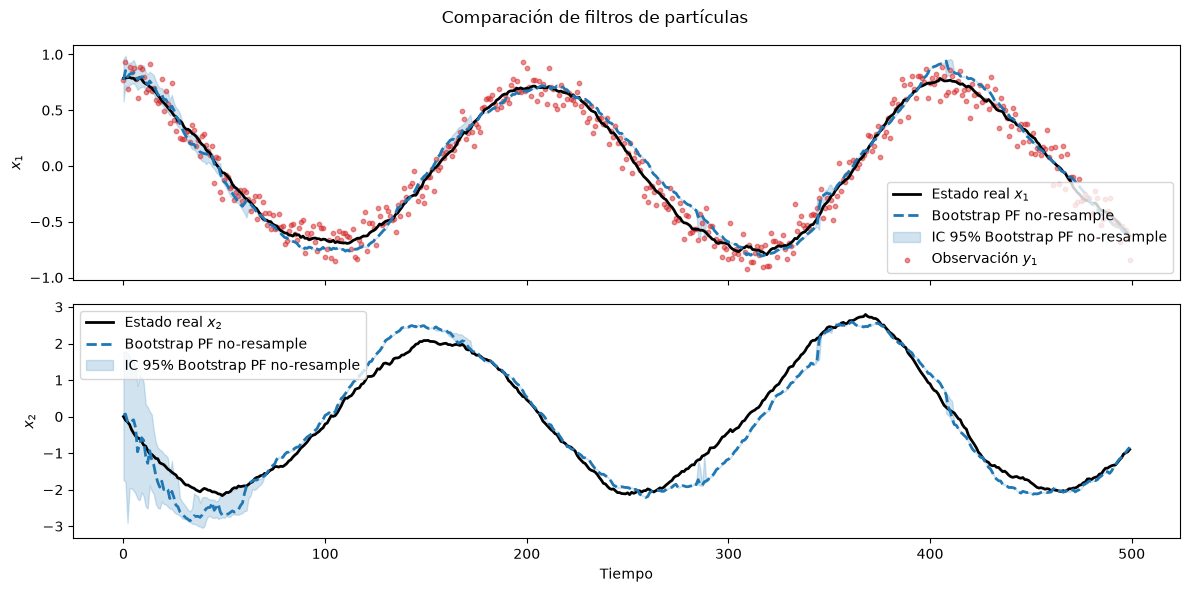

In [12]:
#----Plot Bootstrap Particle Filter sin re-muestreo e info----
print(f"Tiempo de ejecución: {est_bpf_no_resample["execution_time"]}\n")
print(f"Numero de re-muestreos: {est_bpf_no_resample["number_resamples"]}\n")
print(f"Log-verosimilitud estimada: {est_bpf_no_resample["log_likelihood"]}\n")

estimate = { "Bootstrap PF no-resample": est_bpf_no_resample["estimates"] }
intervals = { "Bootstrap PF no-resample": est_bpf_no_resample["intervals"] }

plot_results(x_true, y_obs, estimate, intervals)

### Comparacion Auxiliary Particle Filter con y sin re-muestreo

In [13]:
apf = AuxiliaryParticleFilter(
    N=1000,
    transition_model=transition,
    observation_model=observation
)

apf.initialize(mean=np.array([0.0, 0.0]), cov=np.eye(2))

est_apf = apf.run_filter(y_obs, resample_threshold=500)

In [14]:
apf.reset(mean=np.array([0.0, 0.0]), cov=np.eye(2))

est_apf_no_resample = apf.run_filter(y_obs)

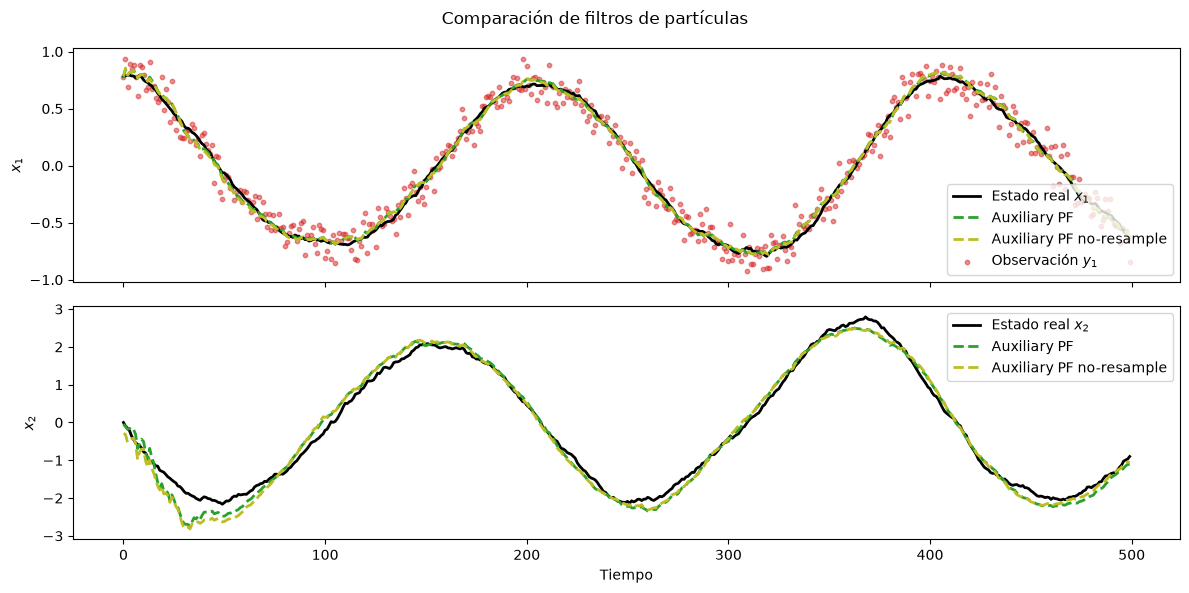

In [15]:
#-----Plot resultados-----
estimates = {
    "Auxiliary PF": est_apf["estimates"],
    "Auxiliary PF no-resample":est_apf_no_resample["estimates"]
}

plot_results(x_true, y_obs, estimates)

Tiempo de ejecución: 104.27631639968604

Numero de re-muestreos: 0

Log-verosimilitud estimada: 416.78600009000473



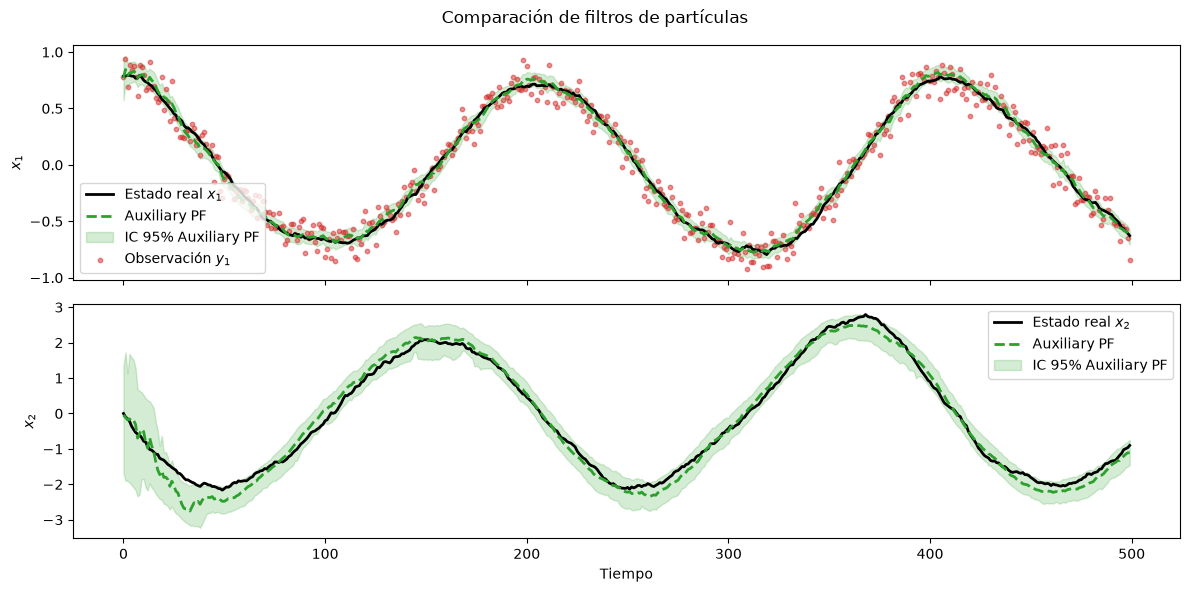

In [19]:
#----Plot Auxiliary Particle Filter con re-muestreo e info----
print(f"Tiempo de ejecución: {est_apf["execution_time"]}\n")
print(f"Numero de re-muestreos: {est_apf["number_resamples"]}\n")
print(f"Log-verosimilitud estimada: {est_apf["log_likelihood"]}\n")

estimate = { "Auxiliary PF": est_apf["estimates"] }
intervals = { "Auxiliary PF": est_apf["intervals"] }

plot_results(x_true, y_obs, estimate, intervals)

Tiempo de ejecución: 108.21926639974117

Numero de re-muestreos: 0

Log-verosimilitud estimada: 414.2393926400787



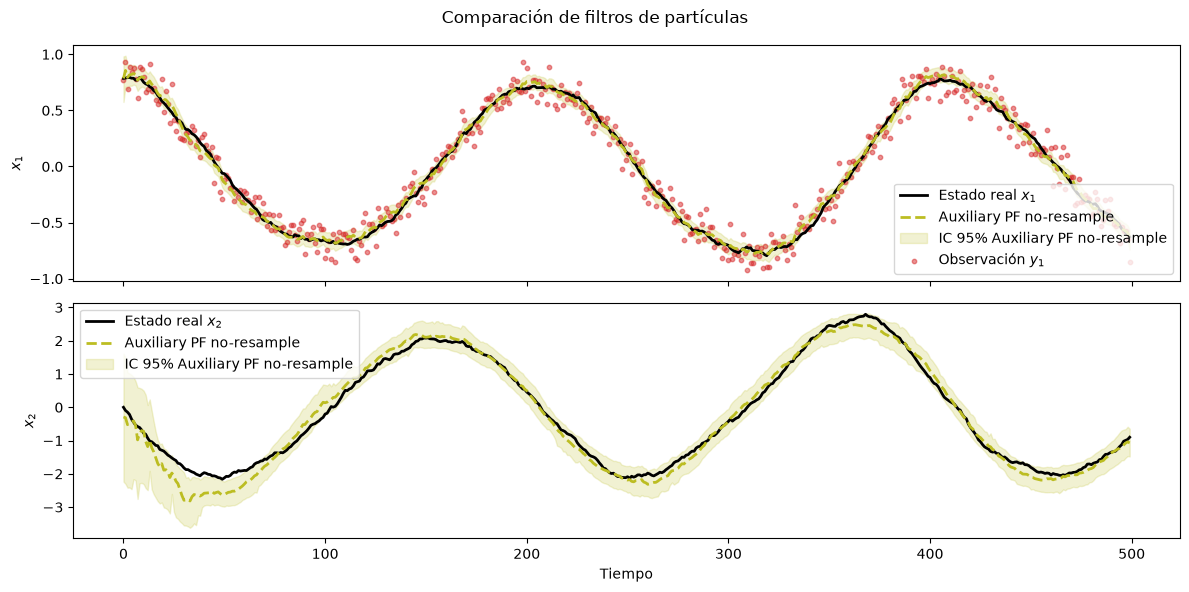

In [20]:
#----Plot Auxiliary Particle Filter sin re-muestreo e info----
print(f"Tiempo de ejecución: {est_apf_no_resample["execution_time"]}\n")
print(f"Numero de re-muestreos: {est_apf_no_resample["number_resamples"]}\n")
print(f"Log-verosimilitud estimada: {est_apf_no_resample["log_likelihood"]}\n")

estimate = { "Auxiliary PF no-resample": est_apf_no_resample["estimates"] }
intervals = { "Auxiliary PF no-resample": est_apf_no_resample["intervals"] }

plot_results(x_true, y_obs, estimate, intervals)

### Comparación Bootstrap Particle Filter vs Auxiliary Paticle Filter

Bootstrap Particle Filter 

Tiempo de ejecución: 45.29452379979193

Numero de re-muestreos: 53

Log-verosimilitud estimada: 413.77738361478185

Auxiliary Particle Filter 

Tiempo de ejecución: 104.27631639968604

Numero de re-muestreos: 0

Log-verosimilitud estimada: 416.78600009000473



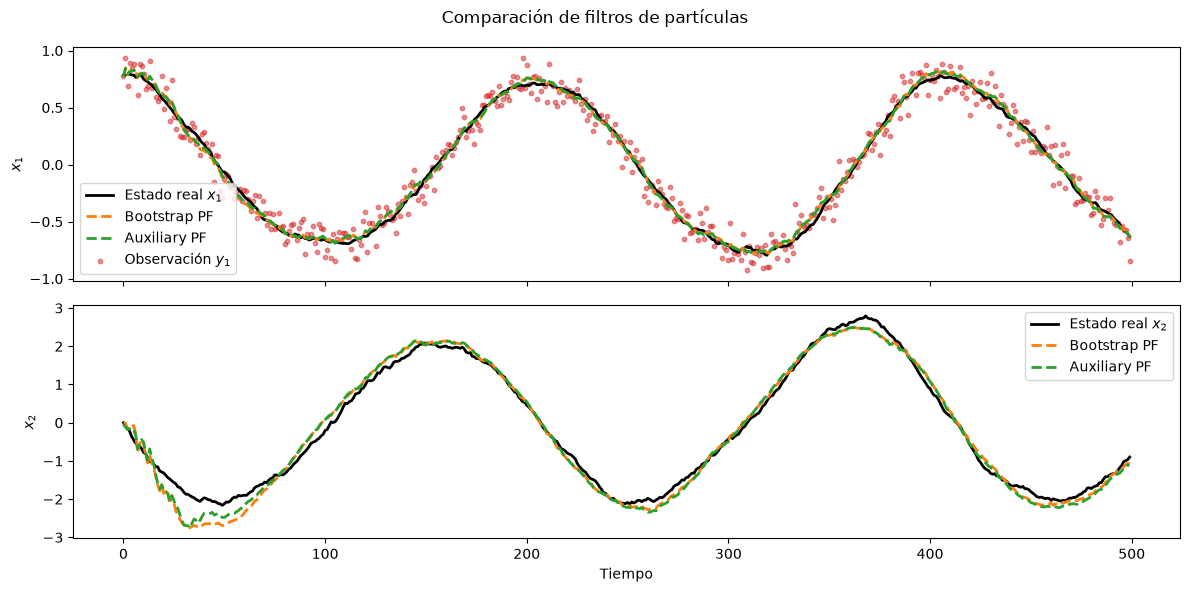

In [22]:
#-----Plot resultados-----
print("Bootstrap Particle Filter \n")
print(f"Tiempo de ejecución: {est_bpf["execution_time"]}\n")
print(f"Numero de re-muestreos: {est_bpf["number_resamples"]}\n")
print(f"Log-verosimilitud estimada: {est_bpf["log_likelihood"]}\n")


print("Auxiliary Particle Filter \n")
print(f"Tiempo de ejecución: {est_apf["execution_time"]}\n")
print(f"Numero de re-muestreos: {est_apf["number_resamples"]}\n")
print(f"Log-verosimilitud estimada: {est_apf["log_likelihood"]}\n")


estimates = {
    "Bootstrap PF": est_bpf["estimates"],
    "Auxiliary PF":est_apf["estimates"]
}

plot_results(x_true, y_obs, estimates)

### Comparación de filtrado según algoritmo y parámetros 

In [6]:
import json

In [7]:
n_particles = [200, 400, 600, 800, 1000]
number_executions = 10

In [25]:
results_bpf = { "number_particles": [], "execution_time": [], "log_likelihood": [], "RMSE": [] }

for n in n_particles:

    result_bpf_n_part = { "number_particles": np.zeros(number_executions), 
                        "execution_time": np.zeros(number_executions), 
                        "log_likelihood": np.zeros(number_executions), 
                        "RMSE": np.zeros(number_executions) 
                        }

    #Instanciar Bootstrap Particle Filter con n partículas
    bpf = BootstrapParticleFilter(
        N=n,
        transition_model=transition,
        observation_model=observation
    )

    bpf.initialize(mean=np.array([0.0, 0.0]), cov=np.eye(2))

    for i in range(number_executions):

        #Ejecutar filtro
        result = bpf.run_filter(y_obs, resample_threshold=500)

        for key in result_bpf_n_part:
            if key == "RMSE":
                result_bpf_n_part[key][i] = RMSE(x_true, result["estimates"])
            
            else:
                result_bpf_n_part[key][i] = result[key]

        bpf.reset(mean=np.array([0.0, 0.0]), cov=np.eye(2))
    
    for key in results_bpf.keys():
        results_bpf[key].append(np.mean(result_bpf_n_part[key]))

    print(f"Filtro con {n} particulas finalizado")


with open("bootsrap_results.json", "w", encoding="utf-8") as file:

    json.dump(results_bpf, file, indent=4)

Filtro con 200 particulas finalizado
Filtro con 400 particulas finalizado
Filtro con 600 particulas finalizado
Filtro con 800 particulas finalizado
Filtro con 1000 particulas finalizado


In [12]:
results_bpf_no_resample = { "number_particles": [], "execution_time": [], "log_likelihood": [], "RMSE": [] }

for n in n_particles:

    result_bpf_nr_n_part = { "number_particles": np.zeros(number_executions), 
                        "execution_time": np.zeros(number_executions), 
                        "log_likelihood": np.zeros(number_executions), 
                        "RMSE": np.zeros(number_executions) 
                        }

    #Instanciar Bootstrap Particle Filter con n partículas
    bpf_nr = BootstrapParticleFilter(
        N=n,
        transition_model=transition,
        observation_model=observation
    )

    bpf_nr.initialize(mean=np.array([0.0, 0.0]), cov=np.eye(2))

    for i in range(number_executions):

        #Ejecutar filtro
        result = bpf_nr.run_filter(y_obs)

        for key in result_bpf_nr_n_part:
            if key == "RMSE":
                result_bpf_nr_n_part[key][i] = RMSE(x_true, result["estimates"])
            
            else:
                result_bpf_nr_n_part[key][i] = result[key]

        if i==4:
            print(f"Iteracion {i+1} con {n} partículas finalizado")

        bpf_nr.reset(mean=np.array([0.0, 0.0]), cov=np.eye(2))
    
    for key in results_bpf_no_resample.keys():
        results_bpf_no_resample[key].append(np.mean(result_bpf_nr_n_part[key]))

    print(f"Filtro con {n} particulas finalizado")


with open("bootsrap_nr_results.json", "w", encoding="utf-8") as file:

    json.dump(results_bpf_no_resample, file, indent=4)

Iteracion 4 con 200 partículas
Filtro con 200 particulas finalizado
Iteracion 4 con 400 partículas
Filtro con 400 particulas finalizado
Iteracion 4 con 600 partículas
Filtro con 600 particulas finalizado
Iteracion 4 con 800 partículas
Filtro con 800 particulas finalizado
Iteracion 4 con 1000 partículas
Filtro con 1000 particulas finalizado


In [10]:
results_apf = { "number_particles": [], "execution_time": [], "log_likelihood": [], "RMSE": [] }

for n in n_particles:

    result_apf_n_part = { "number_particles": np.zeros(number_executions), 
                        "execution_time": np.zeros(number_executions), 
                        "log_likelihood": np.zeros(number_executions), 
                        "RMSE": np.zeros(number_executions) 
                        }

    #Instanciar Bootstrap Particle Filter con n partículas
    apf = AuxiliaryParticleFilter(
        N=n,
        transition_model=transition,
        observation_model=observation
    )

    apf.initialize(mean=np.array([0.0, 0.0]), cov=np.eye(2))

    for i in range(number_executions):

        #Ejecutar filtro
        result = apf.run_filter(y_obs, resample_threshold=500)

        for key in result_apf_n_part:
            if key == "RMSE":
                result_apf_n_part[key][i] = RMSE(x_true, result["estimates"])
            
            else:
                result_apf_n_part[key][i] = result[key]

        if i==4:
            print(f"Iteracion {i+1} con {n} partículas finalizado")

        apf.reset(mean=np.array([0.0, 0.0]), cov=np.eye(2))
    
    for key in results_apf.keys():
        results_apf[key].append(np.mean(result_apf_n_part[key]))

    print(f"Filtro con {n} particulas finalizado")


with open("auxiliaryPF_results.json", "w", encoding="utf-8") as file:

    json.dump(results_apf, file, indent=4)

Iteracion 5 con 200 partículas finalizado
Filtro con 200 particulas finalizado
Iteracion 5 con 400 partículas finalizado
Filtro con 400 particulas finalizado
Iteracion 5 con 600 partículas finalizado
Filtro con 600 particulas finalizado
Iteracion 5 con 800 partículas finalizado
Filtro con 800 particulas finalizado
Iteracion 5 con 1000 partículas finalizado
Filtro con 1000 particulas finalizado


In [11]:
results_apf_nr = { "number_particles": [], "execution_time": [], "log_likelihood": [], "RMSE": [] }

for n in n_particles:

    result_apf_nr_n_part = { "number_particles": np.zeros(number_executions), 
                        "execution_time": np.zeros(number_executions), 
                        "log_likelihood": np.zeros(number_executions), 
                        "RMSE": np.zeros(number_executions) 
                        }

    #Instanciar Bootstrap Particle Filter con n partículas
    apf_nr = AuxiliaryParticleFilter(
        N=n,
        transition_model=transition,
        observation_model=observation
    )

    apf_nr.initialize(mean=np.array([0.0, 0.0]), cov=np.eye(2))

    for i in range(number_executions):

        #Ejecutar filtro
        result = apf_nr.run_filter(y_obs)

        for key in result_apf_nr_n_part:
            if key == "RMSE":
                result_apf_nr_n_part[key][i] = RMSE(x_true, result["estimates"])
            
            else:
                result_apf_nr_n_part[key][i] = result[key]

        if i==4:
            print(f"Iteracion {i+1} con {n} partículas finalizado")

        apf_nr.reset(mean=np.array([0.0, 0.0]), cov=np.eye(2))
    
    for key in results_apf_nr.keys():
        results_apf_nr[key].append(np.mean(result_apf_nr_n_part[key]))

    print(f"Filtro con {n} particulas finalizado")


with open("auxiliaryPF_nr_results.json", "w", encoding="utf-8") as file:

    json.dump(results_apf_nr, file, indent=4)

Iteracion 5 con 200 partículas finalizado
Filtro con 200 particulas finalizado
Iteracion 5 con 400 partículas finalizado
Filtro con 400 particulas finalizado
Iteracion 5 con 600 partículas finalizado
Filtro con 600 particulas finalizado
Iteracion 5 con 800 partículas finalizado
Filtro con 800 particulas finalizado
Iteracion 5 con 1000 partículas finalizado
Filtro con 1000 particulas finalizado


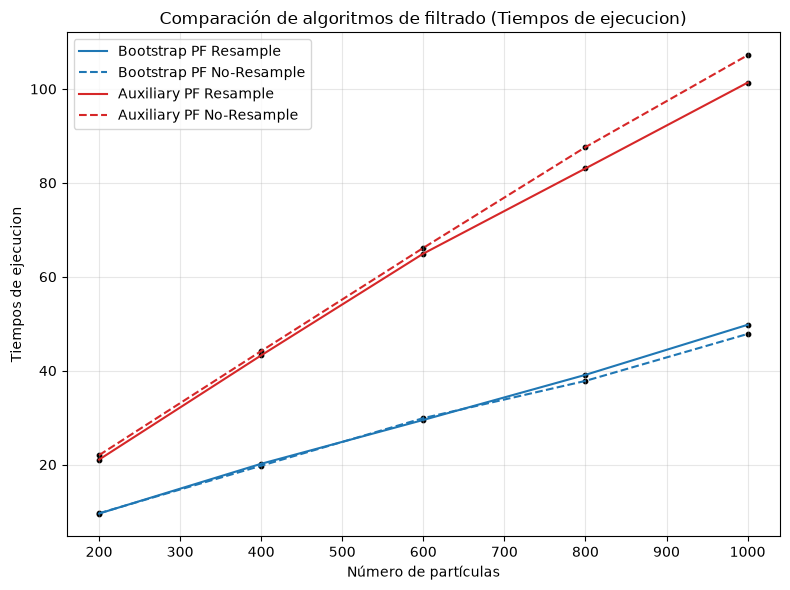

In [13]:
res = {
    "Bootstrap PF Resample": { "number_particles": results_bpf["number_particles"], "execution_time": results_bpf["execution_time"] },
    "Bootstrap PF No-Resample": { "number_particles": results_bpf_no_resample["number_particles"], "execution_time": results_bpf_no_resample["execution_time"] },
    "Auxiliary PF Resample":    { "number_particles": results_apf["number_particles"], "execution_time": results_apf["execution_time"] },
    "Auxiliary PF No-Resample":    { "number_particles": results_apf_nr["number_particles"], "execution_time": results_apf_nr["execution_time"] }
}

plot_comparisons(res, performance_metric="Tiempos de ejecucion")

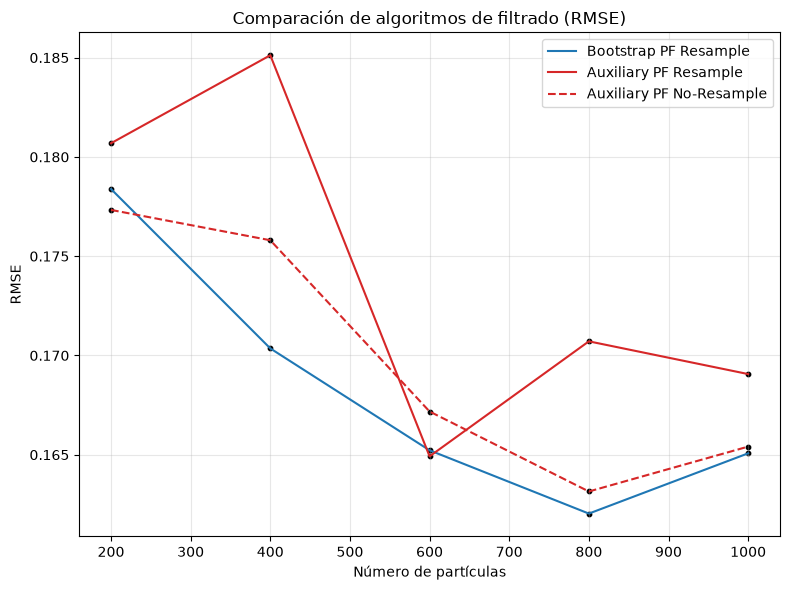

In [15]:
res = {
    "Bootstrap PF Resample": { "number_particles": results_bpf["number_particles"], "RMSE": results_bpf["RMSE"] },
    #"Bootstrap PF No-Resample": { "number_particles": results_bpf_no_resample["number_particles"], "RMSE": results_bpf_no_resample["RMSE"] },
    "Auxiliary PF Resample":    { "number_particles": results_apf["number_particles"], "RMSE": results_apf["RMSE"] },
    "Auxiliary PF No-Resample":    { "number_particles": results_apf_nr["number_particles"], "RMSE": results_apf_nr["RMSE"] }
}

plot_comparisons(res, performance_metric="RMSE")

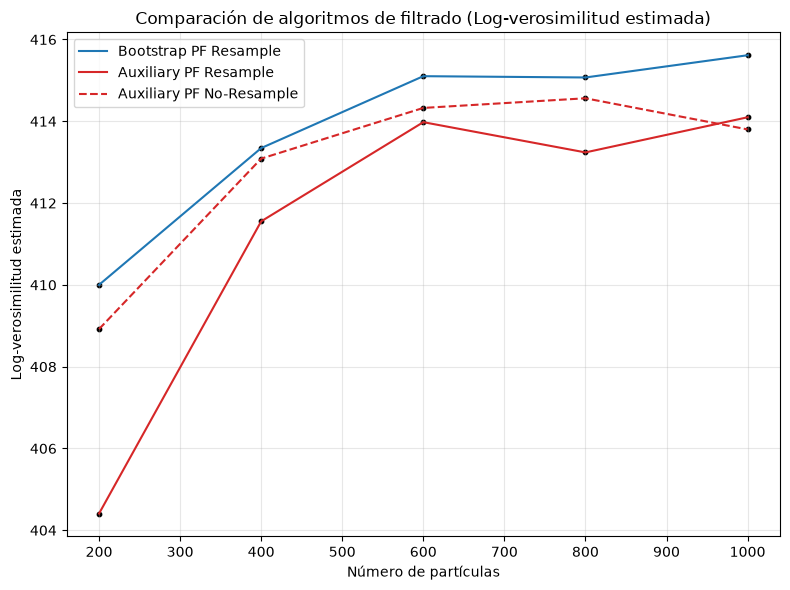

In [17]:
res = {
    "Bootstrap PF Resample": { "number_particles": results_bpf["number_particles"], "log_likelihood": results_bpf["log_likelihood"] },
    #"Bootstrap PF No-Resample": { "number_particles": results_bpf_no_resample["number_particles"], "log_likelihood": results_bpf_no_resample["log_likelihood"] },
    "Auxiliary PF Resample":    { "number_particles": results_apf["number_particles"], "log_likelihood": results_apf["log_likelihood"] },
    "Auxiliary PF No-Resample":    { "number_particles": results_apf_nr["number_particles"], "log_likelihood": results_apf_nr["log_likelihood"] }
}

plot_comparisons(res, performance_metric="Log-verosimilitud estimada")